# Morse-Smale complex (MSC) graph barycenter

Compute a (partial) Fused Gromov–Wasserstein barycenter for a family of **Morse-Smale complexes** loaded from `./data/`, using a **combined adjacency + shortest-path** relation matrix (or plain adjacency / shortest-path / heat-kernel).

This notebook mirrors the demo pipeline in `graph_barycenter_adjacency.ipynb`, but replaces synthetic graph generation with MSC files (`treeNodes_*.txt` / `treeEdges_*.txt`) via `lib/graph_reader.py`.

**Combined relation** (default): `(1 - adjacency) / alpha_fgw + shortest_path_scaled`. Direct pairs lie in `[0, 1]`; indirect pairs lie in `[1/alpha_fgw, 1/alpha_fgw + 1]`, so FGW couplings do not mix direct and indirect structure when `1/alpha_fgw > lambda_penalty`. After barycenter reconstruction, an edge is kept iff the barycenter relation is `<= 1`.

**Pipeline**
1. Select MSC snapshots (mesh indices) from `./data/`.
2. Load each complex as a `networkx.Graph` (`read_morse_graph_txt`), merging duplicate boundary nodes by `(x,y,z)`.
3. Verify connectivity of loaded graphs.
4. Subsample along Morse paths between critical points (critical nodes and degree-≥3 junctions always kept).
5. Visualize processed graphs in the `(x, y)` plane from file coordinates.
6. Build shortest-path relation matrices (normalized) and node features `(x,y,z)` + height for FGW.
7. Run partial FGW (PFGW) barycenter.
8. Reconstruct and visualize the barycenter graph.


In [7]:
# Imports (re-run this cell after editing files under lib/ — no kernel restart needed)
import importlib
import os
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

import ot

import lib.graph_reader as graph_reader
import lib.gromov as gromov
import lib.gromov_barycenter as gromov_barycenter

importlib.reload(graph_reader)
importlib.reload(gromov)
importlib.reload(gromov_barycenter)

from lib.graph_reader import (
    read_morse_graph_txt,
    load_morse_graphs,
    prepare_graph_for_barycenter,
    summarize_graph_connectivity,
    merge_duplicate_nodes,
    sample_morse_graph,
    node_height,
    relation_matrix,
    compute_relation_rescale,
    apply_relation_scaling,
    apply_combined_relation,
    reconstruct_msc_barycenter_mst_graph,
    reconstruct_msc_connectivity_based_graph,
    verify_msc_barycenter_reconstruction,
)
from ot.utils import dist
from lib.gromov import (
    partial_fused_gromov_ver1,
    partial_gromov_ver1,
    gromov_wasserstein,
    GW_dist,
    PGW_dist_with_penalty,
)
from lib.gromov_barycenter import pfgw_barycenters


In [19]:
# --- MSC data configuration ---
DATA_ROOT = Path("data")
# Default demo: VortexStreet MSC snapshots (edit mesh_ids / folder as needed)
# MSC_DIR = DATA_ROOT / "VortexStreet" / "MSC_1.0"
# mesh_ids = [148, 149, 150]  # three nearby time steps
MSC_DIR = DATA_ROOT / "synthetic" / "DESC-MC_1.0"
mesh_ids = [0, 1, 2]


_MSC_NODE_PATTERNS = (
    ("treeNodes_monoMesh_{mesh_id}.txt", "treeEdges_monoMesh_{mesh_id}.txt"),
    ("treeNodes_synthetic_noise_{mesh_id:02d}.txt", "treeEdges_synthetic_noise_{mesh_id:02d}.txt"),
)
_MSC_ID_PATTERNS = (
    re.compile(r"treeNodes_monoMesh_(\d+)\.txt$"),
    re.compile(r"treeNodes_synthetic_noise_(\d+)\.txt$"),
)


def msc_paths(mesh_id: int, msc_dir: Path = MSC_DIR):
    """Return (node_file, edge_file) for a mesh index.

    Supports monoMesh snapshots (treeNodes_monoMesh_*.txt) and synthetic
    noise datasets (treeNodes_synthetic_noise_*.txt).
    """
    for node_pat, edge_pat in _MSC_NODE_PATTERNS:
        node = msc_dir / node_pat.format(mesh_id=mesh_id)
        edge = msc_dir / edge_pat.format(mesh_id=mesh_id)
        if node.exists() and edge.exists():
            return str(node), str(edge)
    raise FileNotFoundError(f"Missing MSC files for mesh {mesh_id} in {msc_dir}")


def list_mesh_ids(msc_dir: Path = MSC_DIR):
    """Discover available mesh indices from treeNodes_*.txt in msc_dir."""
    ids = []
    seen = set()
    for p in sorted(msc_dir.glob("treeNodes_*.txt")):
        for pat in _MSC_ID_PATTERNS:
            m = pat.search(p.name)
            if m:
                mesh_id = int(m.group(1))
                if mesh_id not in seen:
                    seen.add(mesh_id)
                    ids.append(mesh_id)
                break
    return ids


print("MSC directory:", MSC_DIR.resolve())
print("Available meshes (count):", len(list_mesh_ids()))
print("Using mesh_ids:", mesh_ids)


MSC directory: C:\Users\mingz\desktop\MSCBarycenter\data\synthetic\DESC-MC_1.0
Available meshes (count): 5
Using mesh_ids: [0, 1, 2]


In [20]:
def load_msc_nx(mesh_id: int, msc_dir: Path = MSC_DIR):
    """Load one MSC as (nx.Graph, critical_node_ids)."""
    node_f, edge_f = msc_paths(mesh_id, msc_dir)
    G, critical_nodes = read_morse_graph_txt(node_f, edge_f)
    return G, critical_nodes


# prepare_graph_for_barycenter (lib/graph_reader.sample_morse_graph):
# Walk ascending (type 0) and descending (type 1) paths separately. Always keep
# critical nodes and junctions (degree >= 3). Other nodes are kept only when the
# path spacing exceeds sample_rate — higher sample_rate => fewer remaining nodes.


# Load raw MSC graphs
raw_graphs = []
critical_lists = []
for mid in mesh_ids:
    G, crit = load_msc_nx(mid)
    raw_graphs.append(G)
    critical_lists.append(crit)
    print(
        f"mesh {mid}: nodes={G.number_of_nodes()}, edges={G.number_of_edges()}, "
        f"critical={len(crit)}"
    )

# Connectivity check on loaded (unsampled) graphs
print("\n--- Loaded graph connectivity ---")
raw_connectivity = []
for mid, G, crit in zip(mesh_ids, raw_graphs, critical_lists):
    info = summarize_graph_connectivity(G, label=f"loaded mesh {mid}", critical_nodes=crit)
    raw_connectivity.append(info)


mesh 0: nodes=4744, edges=4752, critical=16
mesh 1: nodes=6678, edges=6714, critical=154
mesh 2: nodes=6810, edges=6846, critical=160

--- Loaded graph connectivity ---
[loaded mesh 0] CONNECTED
  nodes=4744, edges=4752, largest component=4744
  critical nodes (id list): 16 in graph, 16 in largest component
  critical nodes (separatrixType=0): 16
[loaded mesh 1] CONNECTED
  nodes=6678, edges=6714, largest component=6678
  critical nodes (id list): 154 in graph, 154 in largest component
  critical nodes (separatrixType=0): 154
[loaded mesh 2] CONNECTED
  nodes=6810, edges=6846, largest component=6810
  critical nodes (id list): 160 in graph, 160 in largest component
  critical nodes (separatrixType=0): 160


In [21]:
# Graphs used for barycenter (path subsampling between critical points)
# sample_rate: minimum spacing between kept regular nodes along each Morse path.
#   - SAMPLE_MODE == "step": spacing in edge hops
#   - SAMPLE_MODE == "geo" : spacing in 3D Euclidean arc length
# Higher sample_rate => sparser graph (fewer nodes). sample_rate == 0 keeps every
# node along each path segment between anchors (critical points + degree>=3 junctions).
SAMPLE_RATE = 0.1
SAMPLE_MODE = "geo"     # 'step' | 'geo'
# 'largest' keeps one connected piece (required for connected subsample); 'full' keeps all components
SAMPLE_COMPONENT = "largest"

Gs = []
critical_lists_sampled = []
for G, crit in zip(raw_graphs, critical_lists):
    H, crit_h = prepare_graph_for_barycenter(
        G,
        critical_nodes=crit,
        sample_rate=SAMPLE_RATE,
        mode=SAMPLE_MODE,
        component=SAMPLE_COMPONENT,
    )
    Gs.append(H)
    critical_lists_sampled.append(crit_h)

print("\n--- Subsampled graph connectivity ---")
for i, G in enumerate(Gs):
    summarize_graph_connectivity(
        G,
        label=f"subsampled mesh {mesh_ids[i]}",
        critical_nodes=critical_lists_sampled[i],
    )



--- Subsampled graph connectivity ---
[subsampled mesh 0] CONNECTED
  nodes=96, edges=104, largest component=96
  critical nodes (id list): 16 in graph, 16 in largest component
  critical nodes (separatrixType=0): 16
[subsampled mesh 1] CONNECTED
  nodes=241, edges=277, largest component=241
  critical nodes (id list): 154 in graph, 154 in largest component
  critical nodes (separatrixType=0): 154
[subsampled mesh 2] CONNECTED
  nodes=253, edges=288, largest component=253
  critical nodes (id list): 160 in graph, 160 in largest component
  critical nodes (separatrixType=0): 160


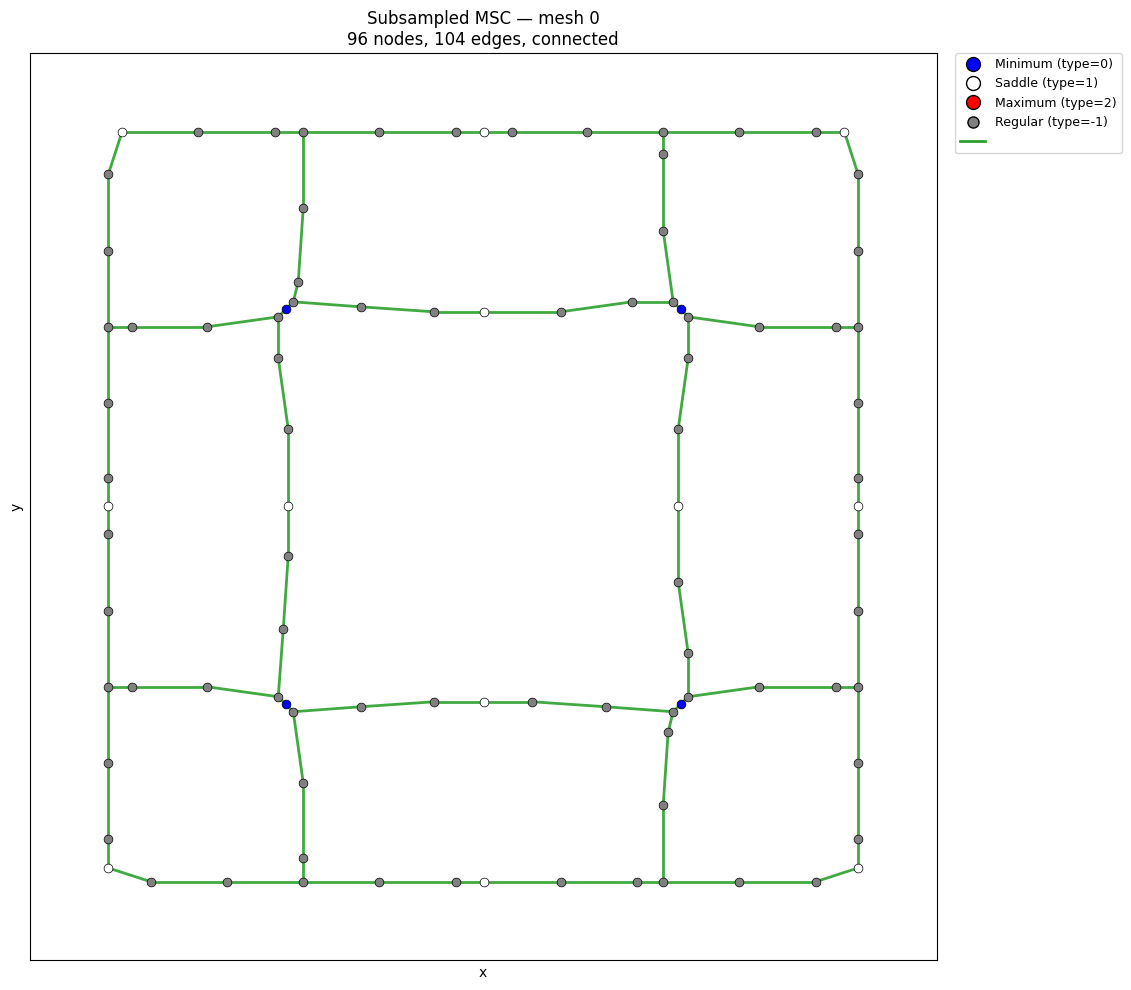

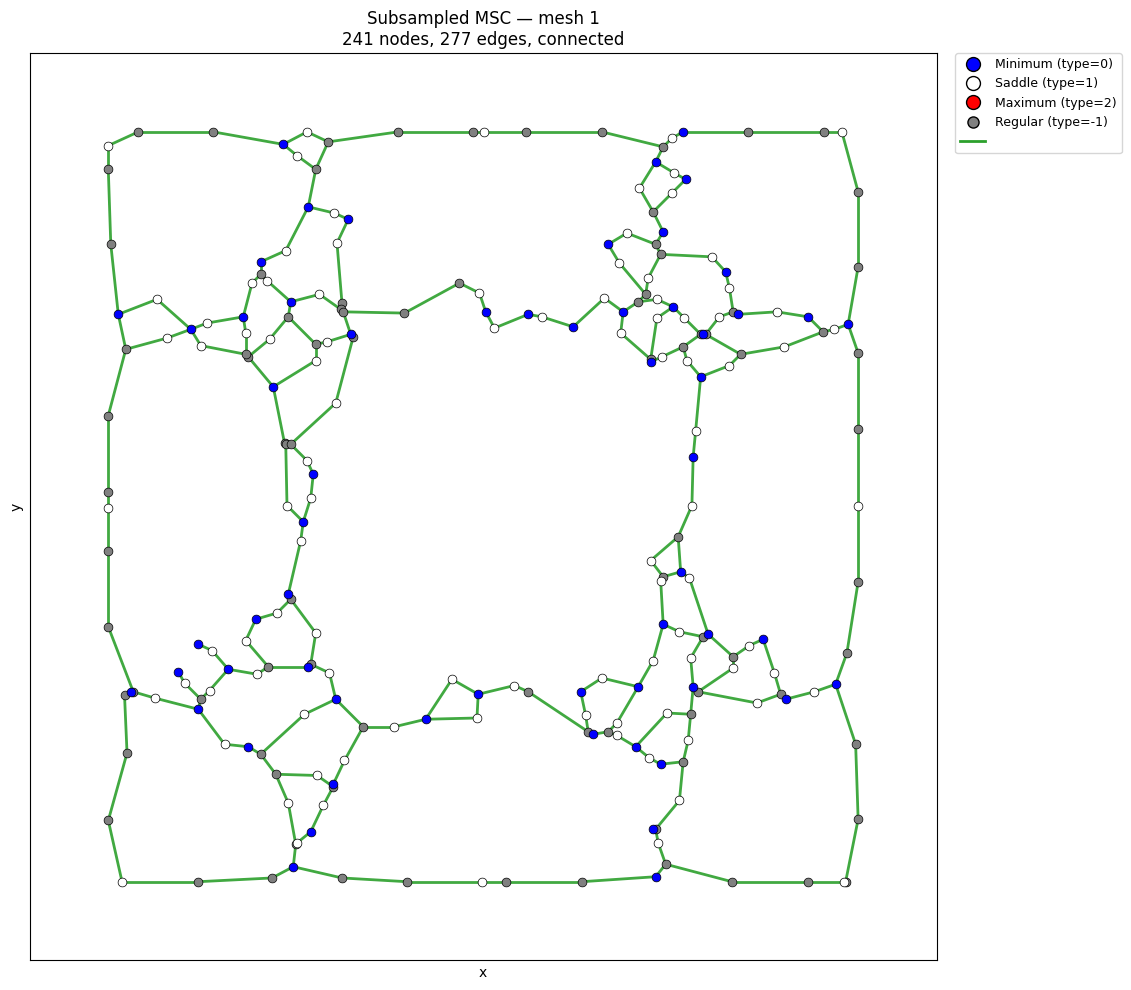

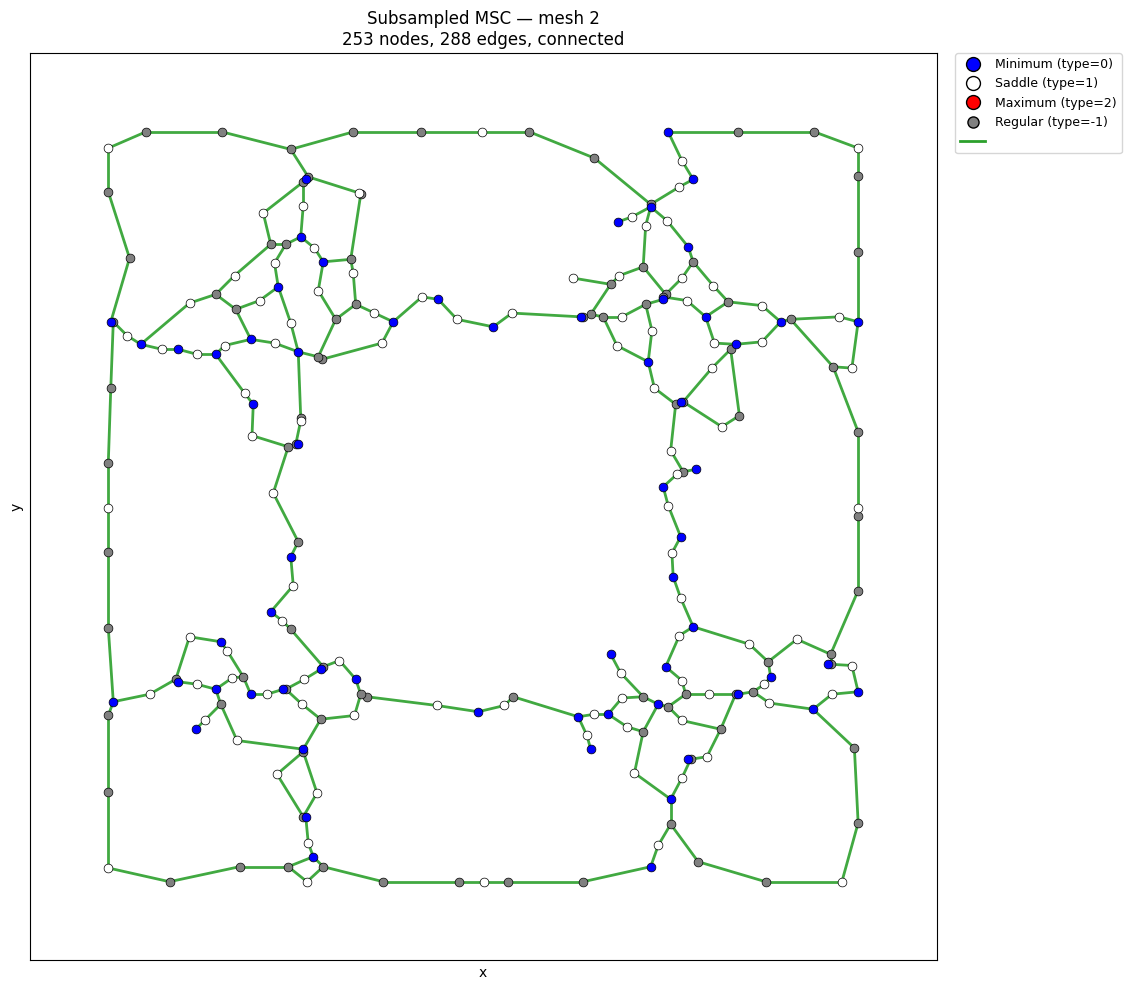

In [25]:
# Visualize processed (subsampled) MSC graphs in the (x, y) plane from file coordinates

from matplotlib.lines import Line2D

from lib.graph_reader import draw_msc_nodes


def msc_xy_positions(G):
    """Layout from node attributes x, y (as stored in the MSC files)."""
    return {n: np.array([G.nodes[n]["x"], G.nodes[n]["y"]], dtype=float) for n in G.nodes()}


def draw_processed_msc_graphs(
    graphs,
    mesh_ids=mesh_ids,
    figsize=(16.0, 10.0),
    critical_size=40,
    regular_size=40,
    edge_width=2.0,
    show_labels=False,
):
    """
    One figure per graph (no subplots). Node IDs are not drawn by default.

    Node colors (from node ``type``):
      - blue  : minimum   (type == 0)
      - white : saddle    (type == 1)
      - red   : maximum   (type == 2)
      - gray  : regular   (type == -1)

    Edge colors (from file column edge type):
      - green : ascending manifold  (type == 0)
      - orange: descending manifold (type == 1)
    """
    legend_handles = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor="blue", markeredgecolor="black", markersize=10, label="Minimum (type=0)"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="white", markeredgecolor="black", markersize=10, label="Saddle (type=1)"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="red", markeredgecolor="black", markersize=10, label="Maximum (type=2)"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", markeredgecolor="black", markersize=8, label="Regular (type=-1)"),
        Line2D([0], [0], color="#2ca02c", linewidth=2),
        # Line2D([0], [0], color="#2ca02c", linewidth=2, label="Ascending edge (type=0)"),
        # Line2D([0], [0], color="#ff7f0e", linewidth=2, label="Descending edge (type=1)"),
    ]

    for i, G in enumerate(graphs):
        fig, ax = plt.subplots(figsize=figsize)
        pos = msc_xy_positions(G)

        edges0 = [(u, v) for u, v, d in G.edges(data=True)] #  if int(d.get("type", 0)) == 0]
        # edges1 = [(u, v) for u, v, d in G.edges(data=True) if int(d.get("type", 0)) == 1]

        if edges0:
            nx.draw_networkx_edges(G, pos, edgelist=edges0, edge_color="#2ca02c", width=edge_width, alpha=0.9, ax=ax)
        # if edges1:
        #     nx.draw_networkx_edges(G, pos, edgelist=edges1, edge_color="#ff7f0e", width=edge_width, alpha=0.9, ax=ax)
        draw_msc_nodes(
            G,
            pos,
            ax,
            regular_size=regular_size,
            critical_size=critical_size,
        )

        if show_labels:
            nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)

        conn = "connected" if nx.is_connected(G) else f"{nx.number_connected_components(G)} components"
        mid = mesh_ids[i] if mesh_ids is not None else i
        ax.set_title(f"Subsampled MSC — mesh {mid}\n{G.number_of_nodes()} nodes, {G.number_of_edges()} edges, {conn}")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_aspect("equal", adjustable="box")
        ax.legend(
            handles=legend_handles,
            loc="upper left",
            bbox_to_anchor=(1.02, 1.0),
            borderaxespad=0.0,
            fontsize=9,
        )
        fig.tight_layout(rect=[0, 0, 0.82, 1])
        plt.show()


draw_processed_msc_graphs(Gs)

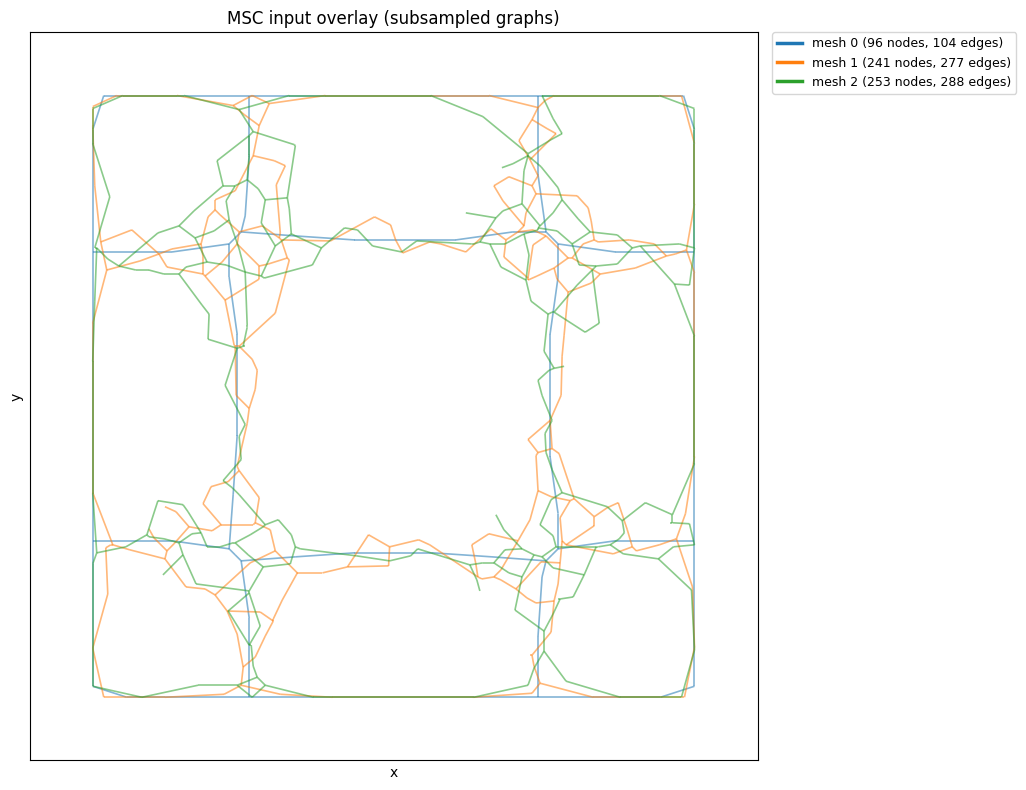

In [23]:
# Overlay all input MSC graphs in one (x, y) view — one edge color per mesh
# Requires cell above (msc_xy_positions). Re-run that cell if needed.

from matplotlib.lines import Line2D

from lib.graph_reader import draw_msc_nodes


def draw_msc_graphs_overlay(
    graphs,
    mesh_ids=None,
    edge_colors=None,
    figsize=(16.0, 8.0),
    edge_width=1.2,
    edge_alpha=0.55,
    show_nodes=False,
    node_size=8,
    node_color="#333333",
    node_alpha=0.25,
):
    """
    Draw subsampled MSC graphs on top of each other for shape comparison.

    Each input graph uses a single edge color (ascending + descending edges alike).
    """
    if mesh_ids is None:
        mesh_ids = list(range(len(graphs)))
    if edge_colors is None:
        palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
        edge_colors = [palette[i % len(palette)] for i in range(len(graphs))]

    fig, ax = plt.subplots(figsize=figsize)
    legend_handles = []

    for i, G in enumerate(graphs):
        pos = msc_xy_positions(G)
        color = edge_colors[i]
        mid = mesh_ids[i] if i < len(mesh_ids) else i

        edgelist = list(G.edges())
        if edgelist:
            nx.draw_networkx_edges(
                G,
                pos,
                edgelist=edgelist,
                edge_color=color,
                width=edge_width,
                alpha=edge_alpha,
                ax=ax,
            )

        if show_nodes and G.number_of_nodes() > 0:
            draw_msc_nodes(
                G,
                pos,
                ax,
                regular_size=node_size,
                critical_size=node_size,
            )

        legend_handles.append(
            Line2D(
                [0],
                [0],
                color=color,
                linewidth=2.5,
                label=f"mesh {mid} ({G.number_of_nodes()} nodes, {G.number_of_edges()} edges)",
            )
        )

    ax.set_title("MSC input overlay (subsampled graphs)")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(
        handles=legend_handles,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0,
        fontsize=9,
    )
    fig.tight_layout(rect=[0, 0, 0.78, 1])
    plt.show()


draw_msc_graphs_overlay(Gs, mesh_ids=mesh_ids)

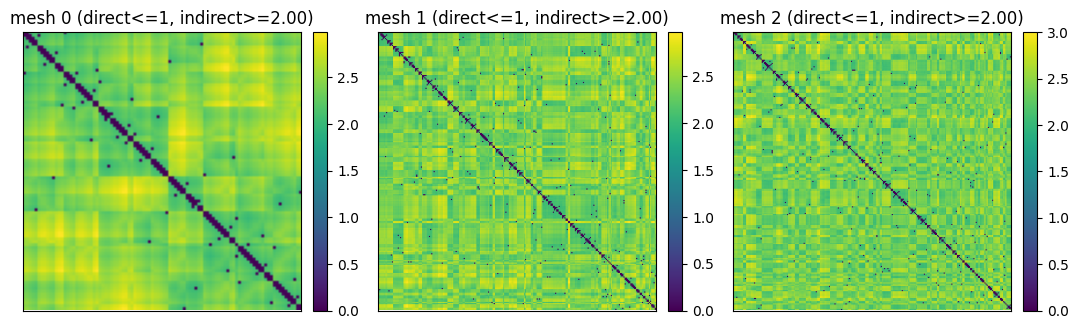

In [24]:
# Relation matrices (lib/graph_reader.relation_matrix — reload after edits)
import importlib
import lib.graph_reader as graph_reader

importlib.reload(graph_reader)
from lib.graph_reader import (
    relation_matrix,
    compute_relation_rescale,
    apply_relation_scaling,
    apply_combined_relation,
)


def show_relation_matrices(
    graphs,
    kind="adjacency",
    cmap="viridis",
    sp_weighted=True,
    *,
    alpha_fgw=0.5,
    relation_rescale=1.0,
):
    n = len(graphs)
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 3.2), squeeze=False)
    for i, G in enumerate(graphs):
        if kind in ("shortestpath", "combined"):
            C, nodes = relation_matrix(G, kind="shortestpath", sp_weighted=sp_weighted)
            C = apply_relation_scaling(C, "shortestpath", relation_rescale, 0.0)
            if kind == "combined":
                A, _ = relation_matrix(G, kind="adjacency", nodelist=nodes)
                C = apply_combined_relation(C, A, alpha_fgw)
        else:
            C, _ = relation_matrix(G, kind=kind, sp_weighted=sp_weighted)
        ax = axes[0, i]
        im = ax.imshow(C, cmap=cmap)
        title = f"mesh {mesh_ids[i]}"
        if kind == "combined":
            title += f" (direct<=1, indirect>={1.0 / alpha_fgw:.2f})"
        ax.set_title(title)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()


_preview_rescale, _, _ = compute_relation_rescale(Gs, "combined", sp_weighted=True)
show_relation_matrices(
    Gs,
    kind="combined",
    sp_weighted=True,
    alpha_fgw=0.5,
    relation_rescale=_preview_rescale,
)


In [ ]:
# Barycenter computation (partial FGW / PFGW)
# Combined structure: (1 - adjacency) / alpha_fgw + shortest_path_scaled.
# Direct pairs lie in [0, 1]; indirect pairs lie in [1/alpha_fgw, 1/alpha_fgw + 1].
# Shortest-path distances use summed 3D Euclidean edge lengths (sp_weighted=True).
# Rescale: shortest_path_scaled = shortest_path_raw / max_global_shortest_path.

from lib.gromov import PFGW_dist_with_penalty
def _pfgw_total_cost(C_tmp, X_tmp, log_tmp, debug=False):
    total = 0.0
    for s in range(len(Cs)):
        M_s = dist(X_tmp, Ys[s])
        d, penalty = PFGW_dist_with_penalty(M_s, C_tmp, Cs[s], log_tmp["T"][s], p, ps[s], Lambda_list[s], alpha=alpha_fgw)
        print("d, penalty:", d, penalty)
        total += lambdas[s] * (d + penalty)
    return float(total)

relation_kind = "combined"
laplacian_base = "adjacency"
laplacian_normalization = "none"
tau = 1.0
sp_weighted = True  # sum 3D Euclidean edge lengths (MSC edges store Euclidean dist)
sp_affinity = "exp"
sp_sigma = None
relation_rescale = 1.0
relation_offset = 0.0
lambda_penalty = 0.25
alpha_fgw = 0.5
direct_edge_max = 1.0  # reconstruction: edge iff combined relation <= this value

relation_rescale, relation_offset, rescale_diag = compute_relation_rescale(
    Gs, relation_kind, sp_weighted=sp_weighted
)
print("Rescale diagnostics:", rescale_diag)
print("relation_rescale:", relation_rescale)
print("indirect band starts at 1/alpha_fgw =", 1.0 / alpha_fgw)

use_partial = True
idx_list = list(range(len(Gs)))
n_graphs = len(idx_list)
N_min = max(Gs[idx].number_of_nodes() for idx in idx_list)
N_center = N_min
lambdas = np.ones(n_graphs, dtype=float) / n_graphs
max_iter = 200
bary_tol = 1e-6
random_state = 0
gw_restarts = 10
gw_seed_start = 0

print("lambda_penalty:", lambda_penalty, "alpha_fgw:", alpha_fgw)

# Node features for FGW: normalized (x, y, z) + normalized height
all_x, all_y, all_z = [], [], []
all_heights = []
all_degrees = []
for idx in idx_list:
    G = Gs[idx]
    for n in G.nodes():
        all_x.append(G.nodes[n]["x"])
        all_y.append(G.nodes[n]["y"])
        all_z.append(G.nodes[n]["z"])
        all_heights.append(node_height(G, n))
        all_degrees.append(G.degree(n))

min_x, max_x = min(all_x), max(all_x)
min_y, max_y = min(all_y), max(all_y)
min_z, max_z = min(all_z), max(all_z)
domain_size = np.sqrt((max_x - min_x) ** 2 + (max_y - min_y) ** 2 + (max_z - min_z) ** 2)
domain_size = domain_size if domain_size > 0 else 1.0
min_height, max_height = min(all_heights), max(all_heights)
height_range = max_height - min_height
height_range = height_range if height_range > 0 else 1.0
max_degree = float(max(all_degrees)) if all_degrees else 1.0
max_degree = max_degree if max_degree > 0 else 1.0

Ys = []
Cs = []
nodes_list = []
for idx in idx_list:
    G = Gs[idx]
    C_idx, nodes_idx = relation_matrix(
        G,
        kind="shortestpath",
        laplacian_base=laplacian_base,
        laplacian_normalization=laplacian_normalization,
        tau=tau,
        sp_weighted=sp_weighted,
        sp_affinity=sp_affinity,
        sp_sigma=sp_sigma,
    )
    C_idx = apply_relation_scaling(
        C_idx, "shortestpath", relation_rescale, relation_offset
    )
    if relation_kind == "combined":
        A_idx, _ = relation_matrix(G, kind="adjacency", nodelist=nodes_idx)
        C_idx = apply_combined_relation(C_idx, A_idx, alpha_fgw)
    Cs.append(C_idx)
    nodes_list.append(nodes_idx)

    coords = np.array(
        [
            [
                (G.nodes[n]["x"] - min_x) / domain_size,
                (G.nodes[n]["y"] - min_y) / domain_size,
                (G.nodes[n]["z"] - min_z) / domain_size,
            ]
            for n in nodes_idx
        ],
        dtype=float,
    )
    heights = np.array(
        [(node_height(G, n) - min_height) / height_range for n in nodes_idx],
        dtype=float,
    ).reshape(-1, 1)
    Ys.append(np.column_stack([coords, heights]))

ps = [np.ones(C.shape[0]) for C in Cs]
p = np.ones(N_center)

if use_partial:
    Lambda_list = None if lambda_penalty is None else [lambda_penalty] * n_graphs
    C_center, X_center, log = pfgw_barycenters(
        N=N_center,
        Ys=Ys,
        Cs=Cs,
        ps=ps,
        p=p,
        Lambda_list=Lambda_list,
        lambdas=lambdas,
        alpha=alpha_fgw,
        max_iter=max_iter,
        tol=bary_tol,
        log=True,
        random_state=random_state,
        gw_restarts=gw_restarts,
        gw_seed_start=gw_seed_start,
        debug=True,
    )
    
    cost = _pfgw_total_cost(C_center, X_center, log)
    print("cost:", cost)
else:
    Lambda_list = [1000] * n_graphs
    C_center, X_center, log = pfgw_barycenters(
        N=N_center,
        Ys=Ys,
        Cs=Cs,
        ps=ps,
        p=p,
        Lambda_list=Lambda_list,
        lambdas=lambdas,
        alpha=alpha_fgw,
        max_iter=max_iter,
        tol=bary_tol,
        log=True,
        random_state=random_state,
        gw_restarts=gw_restarts,
        gw_seed_start=gw_seed_start,
        debug=True,
    )

print("relation_kind:", relation_kind)
print("Barycenter matrix shape:", C_center.shape)
print("Barycenter feature shape:", X_center.shape)
if relation_kind in ("shortestpath", "combined"):
    C_center = np.nan_to_num(C_center, nan=np.inf, posinf=np.inf)
elif relation_kind == "adjacency":
    C_center = np.nan_to_num(C_center, nan=0.0)


In [ ]:
# Check what is the cost if all transportation is full zero
print(Lambda_list)
log_fullzero = {"T": []}
for s in range(len(Cs)):
    log_fullzero['T'].append(np.zeros_like(log['T'][s]))
cost_fullzero = _pfgw_total_cost(C_center, X_center, log_fullzero)
print("cost_fullzero:", cost_fullzero)


In [ ]:
plt.imshow(Cs[0])
plt.colorbar()

In [ ]:
plt.imshow(C_center)
plt.colorbar()

In [ ]:
plt.imshow((Cs[0] < 1) & (Cs[0] <= 2))

In [ ]:
# Reconstruct and draw FGW barycenter graph
# Combined relation: keep all direct edges (C_center < direct_edge_max).

import importlib
import lib.graph_reader as graph_reader

importlib.reload(graph_reader)
from lib.graph_reader import (
    reconstruct_msc_connectivity_based_graph,
    verify_msc_barycenter_reconstruction,
    msc_barycenter_weight_euclidean_differences,
    msc_barycenter_weight_euclidean_debug,
    plot_msc_barycenter_weight_euclidean_debug,
    draw_msc_nodes,
)


def draw_msc_barycenter_graph(G, figsize=(16.0, 12.0)):
    from matplotlib.lines import Line2D

    pos = {n: np.array([G.nodes[n]["x"], G.nodes[n]["y"]], dtype=float) for n in G.nodes()}
    fig, ax = plt.subplots(figsize=figsize)

    edges_direct = [(u, v) for u, v, d in G.edges(data=True) if d.get("edge_pass") == "direct"]

    if edges_direct:
        nx.draw_networkx_edges(G, pos, edgelist=edges_direct, width=1.5, alpha=0.7, edge_color="#444444", ax=ax)

    draw_msc_nodes(G, pos, ax, regular_size=5, critical_size=5)

    ax.set_title(
        f"PFGW barycenter — {G.number_of_nodes()} nodes, {G.number_of_edges()} edges"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(
        handles=[
            Line2D([0], [0], color="#444444", linewidth=2, label="Direct edges (C < 1)"),
        ],
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0,
        fontsize=9,
    )
    fig.tight_layout(rect=[0, 0, 0.82, 1])
    plt.show()


G_center = reconstruct_msc_connectivity_based_graph(
    C_center,
    X_center,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    height_min=min_height,
    height_range=height_range,
    max_degree=max_degree,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    sp_weighted=sp_weighted,
    alpha_fgw=alpha_fgw,
    direct_edge_max=direct_edge_max,
)

n_direct = sum(1 for _, _, d in G_center.edges(data=True) if d.get("edge_pass") == "direct")
print(
    f"Barycenter graph: {G_center.number_of_nodes()} nodes, {G_center.number_of_edges()} edges "
    f"(direct={n_direct})"
)

reconstruct_quality_center = verify_msc_barycenter_reconstruction(
    G_center,
    C_center,
    alpha_fgw=alpha_fgw,
    relation_kind=relation_kind,
    direct_edge_max=direct_edge_max,
)
finite_q = reconstruct_quality_center[np.isfinite(reconstruct_quality_center) & (reconstruct_quality_center > 0)]
if finite_q.size:
    print(
        "reconstruction quality (sp / C_target): "
        f"median={np.median(finite_q):.3f}, mean={np.mean(finite_q):.3f}"
    )

# Debug: unscaled edge weight vs 3D Euclidean (inverse of relation_rescale from FGW)
weight_eucl_diffs = msc_barycenter_weight_euclidean_differences(
    G_center, relation_rescale=relation_rescale, relation_offset=relation_offset, relation_kind=relation_kind
)
print("unscaled weight - euclidean (all edges):", weight_eucl_diffs)
debug_info = plot_msc_barycenter_weight_euclidean_debug(
    G_center,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    relation_kind=relation_kind,
    bins=40,
    by_pass=True,
)

draw_msc_barycenter_graph(G_center)


In [ ]:
# Alternative barycenter view: fully connected graph, keep smallest-weight X% of edges
# (does not replace degree-constrained reconstruction above)

from lib.graph_reader import _inverse_relation_weight, draw_msc_nodes
from matplotlib.collections import LineCollection
import matplotlib.colors as mcolors


def barycenter_xy_positions(X_center, min_x, min_y, domain_size):
    """Same (x, y) layout as ``reconstruct_msc_connectivity_based_graph``."""
    X = np.asarray(X_center, dtype=float)
    return {
        i: np.array(
            [min_x + X[i, 0] * domain_size, min_y + X[i, 1] * domain_size],
            dtype=float,
        )
        for i in range(X.shape[0])
    }


def set_barycenter_axes_limits(ax, pos, pad_frac=0.05):
    """Set xlim/ylim from node positions; y-axis span follows data (not forced square)."""
    xs = np.array([p[0] for p in pos.values()], dtype=float)
    ys = np.array([p[1] for p in pos.values()], dtype=float)
    xspan = float(xs.max() - xs.min())
    yspan = float(ys.max() - ys.min())
    xpad = xspan * pad_frac if xspan > 0 else 1.0
    ypad = yspan * pad_frac if yspan > 0 else 1.0
    ax.set_xlim(xs.min() - xpad, xs.max() + xpad)
    ax.set_ylim(ys.min() - ypad, ys.max() + ypad)
    ax.set_aspect("equal", adjustable="box")


def draw_barycenter_thresholded_complete(
    C_center,
    X_center,
    *,
    min_x,
    min_y,
    min_z,
    domain_size,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    edge_fraction_pct=10.0,
    alpha_min=0.2,
    alpha_max=1.0,
    edge_width=1.0,
    edge_color="#1f77b4",
    node_size=5,
    figsize=(16.0, 12.0),
    pos=None,
    pad_frac=0.05,
):
    """
    Visualize the FGW barycenter as a thresholded complete graph.

    - Collect all finite off-diagonal entries of ``C_center`` (unscaled).
    - Keep the ``edge_fraction_pct`` fraction with smallest weight (e.g. 10 => top 10%).
    - Edge alpha: lightest weight => ``alpha_max`` (opaque), heaviest kept => ``alpha_min``.
    """
    C = np.asarray(C_center, dtype=float)
    X = np.asarray(X_center, dtype=float)
    n = C.shape[0]

    if relation_kind in ("shortestpath", "combined"):
        C = np.nan_to_num(C, nan=np.inf, posinf=np.inf)
    else:
        C = np.nan_to_num(C, nan=0.0)

    candidates = []
    for i in range(n):
        for j in range(i + 1, n):
            w_scaled = C[i, j]
            if not np.isfinite(w_scaled) or w_scaled <= 0:
                continue
            if relation_kind == "combined" and w_scaled > direct_edge_max:
                continue
            w = _inverse_relation_weight(
                float(w_scaled),
                relation_kind=relation_kind,
                relation_rescale=relation_rescale,
                relation_offset=relation_offset,
            )
            candidates.append((w, i, j))

    if not candidates:
        print("No finite positive edges in C_center.")
        return

    candidates.sort(key=lambda e: e[0])
    k = max(1, int(np.ceil(len(candidates) * edge_fraction_pct / 100.0)))
    kept = candidates[:k]
    w_min, w_max = kept[0][0], kept[-1][0]

    def weight_to_alpha(w: float) -> float:
        if w_max <= w_min:
            return alpha_max
        t = (w - w_min) / (w_max - w_min)
        return float(alpha_max - t * (alpha_max - alpha_min))

    if pos is None:
        pos = barycenter_xy_positions(X, min_x, min_y, domain_size)

    fig, ax = plt.subplots(figsize=figsize)
    set_barycenter_axes_limits(ax, pos, pad_frac=pad_frac)

    segments = []
    alphas = []
    rgba_base = mcolors.to_rgba(edge_color)
    for w, u, v in kept:
        segments.append([pos[u], pos[v]])
        a = weight_to_alpha(w)
        alphas.append((rgba_base[0], rgba_base[1], rgba_base[2], a))

    if segments:
        lc = LineCollection(segments, colors=alphas, linewidths=edge_width)
        ax.add_collection(lc)

    G_nodes = nx.Graph()
    for n in pos:
        attrs = {}
        if "G_center" in globals() and G_center.has_node(n):
            attrs = dict(G_center.nodes[n])
        G_nodes.add_node(n, **attrs)
    draw_msc_nodes(G_nodes, pos, ax, regular_size=node_size, critical_size=node_size)

    ax.set_title(
        f"Barycenter thresholded complete graph\n"
        f"{len(kept)} / {len(candidates)} edges (smallest {edge_fraction_pct:g}%), "
        f"weight [{w_min:.4g}, {w_max:.4g}]"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    fig.tight_layout()
    plt.show()

    print(
        f"Kept {len(kept)} edges ({edge_fraction_pct:g}% of {len(candidates)} candidates); "
        f"alpha in [{alpha_min}, {alpha_max}] by weight"
    )


# --- tunables ---
EDGE_FRACTION_PCT = 10.0   # show smallest-weight X% of all pairs
ALPHA_MIN = 0.2              # most transparent (heaviest kept edge)
ALPHA_MAX = 1.0              # least transparent (lightest kept edge)

# Use G_center node coordinates when available so framing matches reconstruction exactly
_pos_recon = (
    {n: np.array([G_center.nodes[n]["x"], G_center.nodes[n]["y"]], dtype=float) for n in G_center.nodes()}
    if "G_center" in dir() and G_center.number_of_nodes() == X_center.shape[0]
    else None
)

draw_barycenter_thresholded_complete(
    C_center,
    X_center,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    edge_fraction_pct=EDGE_FRACTION_PCT,
    alpha_min=ALPHA_MIN,
    alpha_max=ALPHA_MAX,
    pos=_pos_recon,
)